## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import time
import joblib
import sklearn
import nltk
from wordcloud import WordCloud
from collections import Counter

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from preprocess import preprocess

print("pandas", pd.__version__)
print("numpy", np.__version__)
print("scikit-learn", sklearn.__version__)
print("nltk", nltk.__version__)

pandas 3.1.1
numpy 2.4.6
scikit-learn 1.9.1
nltk 3.10.4


### Data Collection

In [2]:
df = pd.read_csv("dataset.csv")

with open("intent_map.json") as f:
    intent_map = json.load(f)

names = {}
for number, info in intent_map.items():
    names[int(number)] = info["name"]

class_names = [names[i] for i in range(14)]
print(df.shape)
print(class_names)

(2250, 5)
['branch_address', 'activate_card', 'past_transactions', 'dispatch_status', 'outstanding_balance', 'card_issue', 'ifsc_code', 'generate_pin', 'unauthorised_transaction', 'loan_query', 'balance_enquiry', 'change_limit', 'block', 'lost']


In [3]:
df.head()

,row_id,template_id,text,intent_class,intent_name
0,0,0,Please tell me the IFSC Code,6,ifsc_code
1,1,0,Please tell me the IFSC Code for my savings ac...,6,ifsc_code
2,2,0,Please tell me the IFSC Code of my branch,6,ifsc_code
3,3,0,Please tell me the IFSC Code of my home branch,6,ifsc_code
4,4,0,Please tell me the IFSC Code for neft transfer,6,ifsc_code


In [4]:
print("shape:", df.shape)
df.info()
print(df.isnull().sum())
print("duplicate rows:", df.duplicated().sum())
print("duplicate texts:", df["text"].duplicated().sum())
print(df["intent_class"].value_counts().sort_index())

shape: (2250, 5)
<class 'pandas.DataFrame'>
RangeIndex: 2250 entries, 0 to 2249
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   row_id        2250 non-null   int64
 1   template_id   2250 non-null   int64
 2   text          2250 non-null   str  
 3   intent_class  2250 non-null   int64
 4   intent_name   2250 non-null   str  
dtypes: int64(3), str(2)
memory usage: 211.2 KB
row_id          0
template_id     0
text            0
intent_class    0
intent_name     0
dtype: int64
duplicate rows: 0
duplicate texts: 0
intent_class
0     165
1     150
2     210
3     150
4     165
5     165
6     120
7     150
8      90
9     255
10    150
11    210
12    150
13    120
Name: count, dtype: int64


2,250 rows, 5 columns, nothing missing, no duplicates.
The classes are not equal. Class 9 (loans) has 255 rows and class 8 (fraud) has only 90. That follows the number of templates per class (Phase 3).

### simple text feature engineering

In [5]:
df["word_count"] = df["text"].str.split().str.len()
df["char_count"] = df["text"].str.len()

print(df[["word_count", "char_count"]].describe())
print(df.groupby("intent_name")[["word_count", "char_count"]].mean().round(1))

        word_count   char_count
count  2250.000000  2250.000000
mean      8.544444    43.424889
std       3.131195    14.928551
min       1.000000     8.000000
25%       6.000000    33.000000
50%       8.000000    42.000000
75%      10.000000    52.000000
max      21.000000   112.000000
                          word_count  char_count
intent_name                                     
activate_card                    8.0        39.4
balance_enquiry                  7.7        40.2
block                            8.2        40.2
branch_address                   6.5        34.4
card_issue                       8.4        41.0
change_limit                    12.4        61.0
dispatch_status                  8.4        44.5
generate_pin                     8.7        41.7
ifsc_code                        9.0        37.7
loan_query                       7.4        37.0
lost                             7.6        36.0
outstanding_balance              9.0        51.2
past_transactions         

### word cloud

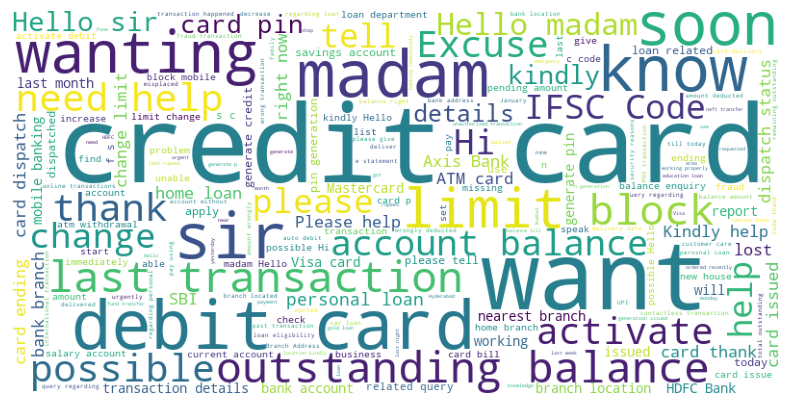

['credit card', 'want', 'debit card', 'madam', 'sir', 'know', 'soon', 'wanting', 'limit', 'outstanding balance', 'last transaction', 'block']


In [6]:
text = " ".join(df["text"].astype(str))
wc = WordCloud(width=800, height=400, background_color="white").generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc)
plt.axis("off")
plt.savefig("docs/wordcloud.png")
plt.show()

print(list(wc.words_.keys())[:12])

### Text preprocessing

In [7]:
print(preprocess("I LOVE This Product!!!"))
print(preprocess("I can't find my debit card, i f s c code please"))

df["clean"] = df["text"].apply(preprocess)

print("empty clean texts:", (df["clean"] == "").sum())
print(df[["text", "clean"]].sample(6, random_state=1).to_string(index=False))

love product
cant find debit card ifsc code please
empty clean texts: 0
                                                          text                                           clean
i want to change limit of my pos transaction on my credit card    want change limit po transaction credit card
                  Excuse me, home loan related query thank you            excuse home loan related query thank
                        Please help me, limit change thank you                  please help limit change thank
           Kindly help me, credit card outstanding balance sir kindly help credit card outstanding balance sir
               How to generate pin for credit card ending 7305            generate pin credit card ending 7305
          i have query regarding personal loan for my business          query regarding personal loan business


 Look at row 1: "pos" became "po" (the lemmatizer thinks "pos" is a plural). Row 2: "Excuse me, ... thank you" became "excuse ... thank". The polite words are still there. We kept them on purpose, because a real caller says them.

In [8]:
for c in range(14):
    words = " ".join(df[df["intent_class"] == c]["clean"]).split()
    top = [w for w, n in Counter(words).most_common(6)]
    print(c, names[c].ljust(26), top)

0 branch_address             ['branch', 'bank', 'location', 'nearest', 'address', 'tell']
1 activate_card              ['card', 'activate', 'debit', 'want', 'credit', 'help']
2 past_transactions          ['transaction', 'last', 'detail', 'account', 'know', 'help']
3 dispatch_status            ['card', 'credit', 'status', 'dispatch', 'dispatched', 'sir']
4 outstanding_balance        ['balance', 'outstanding', 'card', 'credit', 'amount', 'hello']
5 card_issue                 ['card', 'credit', 'not', 'working', 'cannot', 'use']
6 ifsc_code                  ['ifsc', 'code', 'tell', 'know', 'want', 'please']
7 generate_pin               ['pin', 'card', 'generate', 'credit', 'want', 'generation']
8 unauthorised_transaction   ['account', 'transaction', 'fraud', 'report', 'amount', 'deducted']
9 loan_query                 ['loan', 'personal', 'home', 'want', 'madam', 'query']
10 balance_enquiry            ['balance', 'account', 'bank', 'want', 'know', 'enquiry']
11 change_limit               

the keywords make sense. ifsc_code has "ifsc" and "code", lost has "lost" and "missing". But some classes show "madam", "sir", "hello", "please" or "help" in their top words. That is the opener effect again.

### Input - Output separation

In [9]:
X = df["clean"]
y = df["intent_class"]
print(X.shape, y.shape)

(2250,) (2250,)


In [10]:
split = pd.read_csv("data/raw/split_template_ids.csv")
df = df.merge(split, on="template_id", how="left")

is_train = df["split"] == "train"
is_test = df["split"] == "test"

X_train, y_train = X[is_train], y[is_train]
X_test, y_test = X[is_test], y[is_test]
groups_train = df[is_train]["template_id"]

print("train:", len(X_train), "test:", len(X_test))
print("templates in both:", len(set(df[is_train]["template_id"]) & set(df[is_test]["template_id"])))
print("classes in test:", y_test.nunique())

train: 1800 test: 450
templates in both: 0
classes in test: 14


### Text vectorization

In [11]:
vectorizer = FeatureUnion([
    ("word", TfidfVectorizer(ngram_range=(1, 2))),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))),
])

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("train matrix:", X_train_vec.shape)
print("test matrix:", X_test_vec.shape)


def make_pipe(model):
    vec = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2))),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))),
    ])
    return Pipeline([("vec", vec), ("model", model)])

train matrix: (1800, 4069)
test matrix: (450, 4069)


### Baseline Model

In [12]:
baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_vec, y_train)

train_pred = baseline.predict(X_train_vec)
y_pred = baseline.predict(X_test_vec)

print("Train accuracy:", round(accuracy_score(y_train, train_pred), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

Train accuracy: 0.9994
Test accuracy: 0.9689


the model gets 99.9% on the training rows and 96.9% on the test rows. A gap like this is normal, since the model has seen the training sentences. The test score is the one that counts.

### Model Evaluation

Accuracy: 0.9689
Precision (macro): 0.9688
Recall (macro): 0.9452
F1 (macro): 0.9503
                          precision    recall  f1-score   support

          branch_address       1.00      1.00      1.00        30
           activate_card       1.00      1.00      1.00        30
       past_transactions       0.82      1.00      0.90        45
         dispatch_status       0.97      0.97      0.97        30
     outstanding_balance       1.00      0.97      0.98        30
              card_issue       1.00      0.97      0.98        30
               ifsc_code       1.00      1.00      1.00        30
            generate_pin       1.00      1.00      1.00        30
unauthorised_transaction       0.86      0.40      0.55        15
              loan_query       0.98      1.00      0.99        60
         balance_enquiry       1.00      0.97      0.98        30
            change_limit       1.00      1.00      1.00        45
                   block       1.00      0.97      0.98 

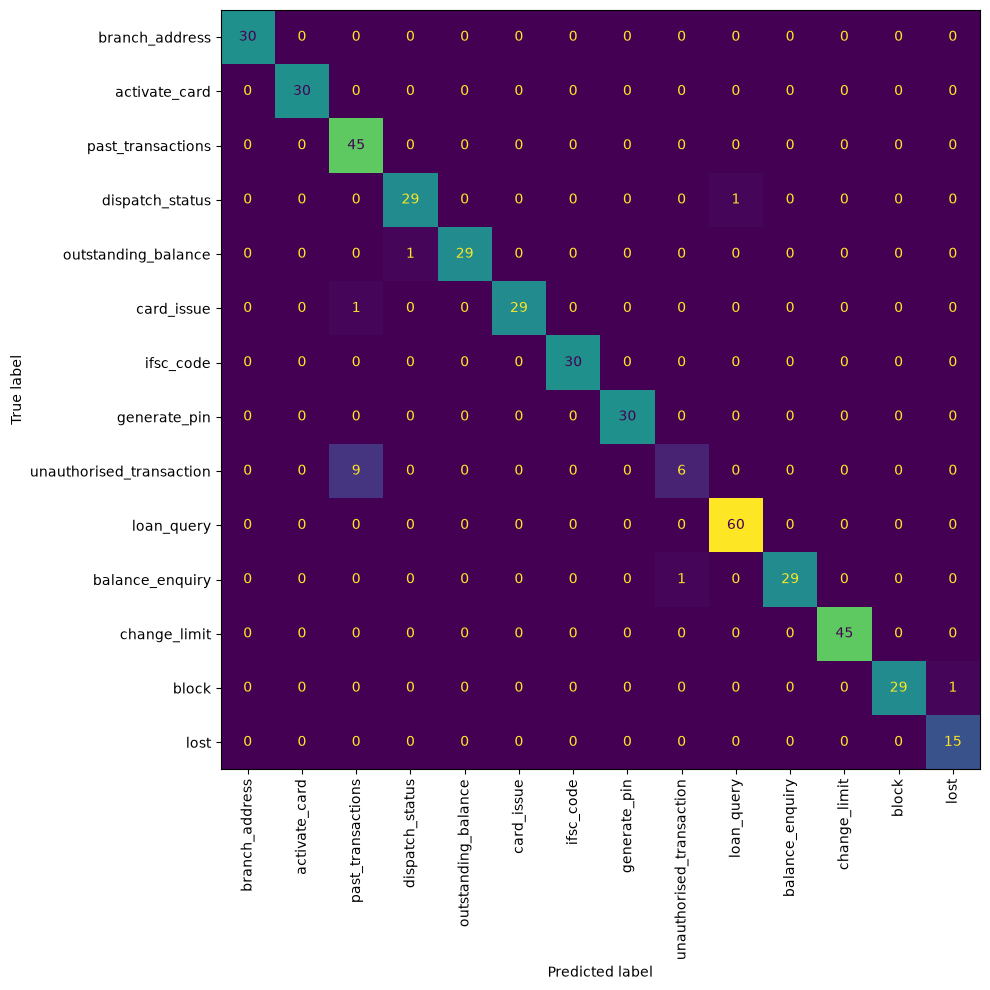

unauthorised_transaction : 6 of 15 correct
block : 29 of 30 correct
lost : 15 of 15 correct
urgent calls that landed in any urgent class: 51 of 60


In [13]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (macro):", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall (macro):", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1 (macro):", round(f1_score(y_test, y_pred, average="macro"), 4))
print(classification_report(y_test, y_pred, target_names=class_names))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, xticks_rotation=90, ax=ax, colorbar=False)
plt.tight_layout()
plt.savefig("docs/confusion_matrix.png")
plt.show()

urgent = [8, 12, 13]
for c in urgent:
    total = (y_test == c).sum()
    right = ((y_test == c) & (y_pred == c)).sum()
    print(names[c], ":", right, "of", total, "correct")

real_urgent = y_test.isin(urgent)
caught = real_urgent & np.isin(y_pred, urgent)
print("urgent calls that landed in any urgent class:", caught.sum(), "of", real_urgent.sum())

### Looking at the mistakes

In [14]:
wrong = df[is_test].copy()
wrong["predicted"] = y_pred
wrong = wrong[wrong["intent_class"] != wrong["predicted"]]
wrong["predicted_name"] = wrong["predicted"].map(names)

print(len(wrong), "wrong rows out of", len(y_test))
print(wrong[["text", "intent_name", "predicted_name"]].to_string(index=False))

14 wrong rows out of 450
                                        text              intent_name           predicted_name
 how much do i need to pay on my credit card      outstanding_balance          dispatch_status
       how much money is there in my account          balance_enquiry unauthorised_transaction
                    Unauthorised transaction unauthorised_transaction        past_transactions
              Unauthorised transaction today unauthorised_transaction        past_transactions
         Unauthorised transaction last night unauthorised_transaction        past_transactions
     Sir, unauthorised transaction thank you unauthorised_transaction        past_transactions
       Hi, unauthorised transaction urgently unauthorised_transaction        past_transactions
         Excuse me, unauthorised transaction unauthorised_transaction        past_transactions
I need help, unauthorised transaction please unauthorised_transaction        past_transactions
        i need help unaut

14 rows are wrong, and 9 of the 14 are variations of one template, the two-word sentence "Unauthorised transaction". The model says past_transactions for all of them. Why? Fraud has only 5 training templates, and the other four use words like "fraud", "deducted", "without my knowledge". The word "unauthorised" is rare in training, and the word "transaction" points strongly to past_transactions. I also searched dataset.csv for the US spelling "unauthorized" and found 0 rows. A caller, a speech model or a translator may well write it that way.

This is a real weakness in the most important class, and the grouped split found it, which is why we use it. The other 5 mistakes are single rows, such as "freeze my debit card" (block) called lost.

### Experiment witht he preprocessing choices

In [15]:
rows = []
for join in [True, False]:
    for remove_stop in [True, False]:
        clean_all = df["text"].apply(preprocess, join=join, remove_stop=remove_stop)
        pipe = make_pipe(LogisticRegression(max_iter=1000))
        pipe.fit(clean_all[is_train], y_train)
        pred = pipe.predict(clean_all[is_test])
        rows.append({"join_letters": join, "remove_stopwords": remove_stop,
                     "accuracy": round(accuracy_score(y_test, pred), 4),
                     "f1_macro": round(f1_score(y_test, pred, average="macro"), 4)})

print(pd.DataFrame(rows).to_string(index=False))

 join_letters  remove_stopwords  accuracy  f1_macro
         True              True    0.9689    0.9503
         True             False    0.9711    0.9455
        False              True    0.9644    0.9456
        False             False    0.9689    0.9421


### Hyperparameter tuning

In [16]:
grid = {
    "model__C": [1, 10, 100],
    "vec__word__ngram_range": [(1, 1), (1, 2)],
    "vec__char__ngram_range": [(2, 4), (2, 5)],
}

search = GridSearchCV(make_pipe(LogisticRegression(max_iter=1000)), grid,
                      cv=GroupKFold(n_splits=5), scoring="f1_macro")

start = time.time()
search.fit(X_train, y_train, groups=groups_train)
print("search took", round(time.time() - start), "seconds")

print("best settings:", search.best_params_)
print("best grouped CV macro F1:", round(search.best_score_, 4))

results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")
print(results[["param_model__C", "param_vec__word__ngram_range", "param_vec__char__ngram_range", "mean_test_score"]].head(6).to_string(index=False))

search took 11 seconds
best settings: {'model__C': 100, 'vec__char__ngram_range': (2, 4), 'vec__word__ngram_range': (1, 2)}
best grouped CV macro F1: 0.9199
 param_model__C param_vec__word__ngram_range param_vec__char__ngram_range  mean_test_score
            100                       (1, 2)                       (2, 4)         0.919947
            100                       (1, 1)                       (2, 5)         0.906515
            100                       (1, 1)                       (2, 4)         0.905744
            100                       (1, 2)                       (2, 5)         0.904172
             10                       (1, 1)                       (2, 4)         0.900069
             10                       (1, 2)                       (2, 4)         0.898595


the best combination is C=100, word n-grams (1, 2), character n-grams (2, 4), with a grouped cross-validation macro F1 of 0.9199. The second best is 0.9065, so there is a clear but not huge gap. Notice this CV score (0.92) is lower than the test score from cell 13 (0.95). That is normal for this data. The CV parts are smaller, and each one leaves out whole templates from the already rare fraud class.


the search picked a large C. Large C means the model fits the training data tightly. The grouped scores show this is fine here, because the check was done on templates the model had not seen.

### Best Model Selection

In [17]:
best = search.best_params_
vec_settings = {}
for key, value in best.items():
    if key.startswith("vec__"):
        vec_settings[key] = value

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=best["model__C"]),
    "Calibrated LinearSVC": CalibratedClassifierCV(LinearSVC(), cv=3),
    "Naive Bayes": MultinomialNB(),
}

fitted = {}
rows = []
for name, model in models.items():
    pipe = make_pipe(model)
    pipe.set_params(**vec_settings)

    cv_scores = cross_val_score(pipe, X_train, y_train, cv=GroupKFold(n_splits=5),
                                groups=groups_train, scoring="f1_macro")
    pipe.fit(X_train, y_train)

    start = time.time()
    pred = pipe.predict(X_test)
    ms = (time.time() - start) / len(X_test) * 1000

    fitted[name] = pipe
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, average="macro"),
        "recall": recall_score(y_test, pred, average="macro"),
        "f1": f1_score(y_test, pred, average="macro"),
        "train_f1": f1_score(y_train, pipe.predict(X_train), average="macro"),
        "cv_f1": cv_scores.mean(),
        "ms_per_sentence": ms,
    })

table = pd.DataFrame(rows).set_index("model")
table["gap"] = table["train_f1"] - table["cv_f1"]
print(table.round(3).to_string())

best_name = table["cv_f1"].idxmax()
print("best by grouped CV F1:", best_name)

                      accuracy  precision  recall     f1  train_f1  cv_f1  ms_per_sentence    gap
model                                                                                            
Logistic Regression      0.976      0.974   0.955  0.959     1.000  0.920            0.036  0.080
Calibrated LinearSVC     0.978      0.978   0.960  0.965     1.000  0.903            0.040  0.097
Naive Bayes              0.973      0.982   0.952  0.960     0.988  0.865            0.033  0.123
best by grouped CV F1: Logistic Regression


Decision: Logistic Regression wins by the rule. It also gives probabilities by itself, and Phase 7 depends on them. Write that reason in the notebook. A caution on the calibrated LinearSVC: its internal calibration uses plain 3-fold cuts and not grouped ones, so its probabilities could look better than they are.

### checking the Confidence Score

In [18]:
final = fitted[best_name]

probs = final.predict_proba(X_test)
top_prob = probs.max(axis=1)
pred = final.predict(X_test)

check = pd.DataFrame({"top_prob": top_prob, "right": pred == y_test.values})
check["bucket"] = pd.cut(check["top_prob"], [0, 0.5, 0.7, 0.9, 1.0])
print(check.groupby("bucket", observed=True)["right"].agg(["count", "mean"]).round(3))

high = check[check["top_prob"] >= 0.9]
print("predictions with probability 0.9 or more:", len(high))
print("share of those that were correct:", round(high["right"].mean(), 4))
print("average top probability:", round(check["top_prob"].mean(), 3))

            count   mean
bucket                  
(0.0, 0.5]      2  1.000
(0.5, 0.7]     12  0.333
(0.7, 0.9]     23  0.870
(0.9, 1.0]    413  1.000
predictions with probability 0.9 or more: 413
share of those that were correct: 1.0
average top probability: 0.97


The scores mean something. When the model is unsure (below 0.7), it is wrong a lot. When it says 0.9 or more, it was right on all 413 test rows. That is exactly what Phase 7 needs: a threshold of about 0.9 keeps the wrong ones out.

The honest limit: the test rows are written with the same method as the training rows, so real speech will score lower. Cell 22 shows a first example. Do not quote "100% above 0.9" as a result for real calls.

### Bucket scores and polite words

In [19]:
more = pd.read_csv("data/raw/dataset_with_bucket.csv")[["row_id", "bucket"]]
test_rows = df[is_test].merge(more, on="row_id")
test_rows["right"] = (final.predict(test_rows["clean"]) == test_rows["intent_class"])
print(test_rows.groupby("bucket")["right"].mean().round(4))

OPENER_WORDS = ["hello", "hi", "sir", "madam", "please", "kindly", "thank",
                "urgent", "urgently", "emergency", "hurry", "immediately"]


def remove_openers(text):
    words = [w for w in text.split() if w not in OPENER_WORDS]
    return " ".join(words)


plain = X_test.apply(remove_openers)
plain_pred = final.predict(plain)
print("rows that changed:", (plain != X_test).sum())
print("accuracy with opener words:", round(accuracy_score(y_test, final.predict(X_test)), 4))
print("accuracy without them:", round(accuracy_score(y_test, plain_pred), 4))

bucket
1    0.9867
2    0.9533
3    0.9867
Name: right, dtype: float64
rows that changed: 196
accuracy with opener words: 0.9756
accuracy without them: 0.9756


Bucket 1 (concrete) is 0.9867, bucket 2 (polite and spoken) is 0.9533, bucket 3 (noisy) is 0.9867. The noisy bucket is not the weak one, which is good. The polite bucket is lowest, most likely because the polite versions of the weak fraud sentence sit here (I did not check each row).

196 of the 450 test sentences contain at least one of those words. After removing them, accuracy is exactly the same, 0.9756 and 0.9756. So the model does not lean on them for the test rows.


this test is limited. It only removes words from sentences that already had them. It does not prove the model handles a completely new way to say things. Phase 9 does that.

### Saving the model

In [20]:
vectorizer = final.named_steps["vec"]
model = final.named_steps["model"]

joblib.dump(model, "best_model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")

info = {"model": best_name, "settings": {k: str(v) for k, v in vec_settings.items()},
        "train_rows": len(X_train), "seed": 42}
with open("model_info.json", "w") as f:
    json.dump(info, f, indent=2)

print("saved:", best_name)

saved: Logistic Regression


### Loading the Saved Files

In [21]:
model2 = joblib.load("best_model.pkl")
vectorizer2 = joblib.load("vectorizer.pkl")


def predict_one(sentence):
    clean_text = preprocess(sentence)
    vec = vectorizer2.transform([clean_text])
    probs = model2.predict_proba(vec)[0]
    best_index = probs.argmax()
    return int(model2.classes_[best_index]), round(float(probs[best_index]), 3)


tests = [
    ("my card is lost", 13),
    ("I can't find my card anywhere", 13),
    ("my card is not working at the shop", 5),
    ("I did not make this payment", 8),
    ("what is the ifsc code", 6),
    ("i f s c code of my branch", 6),
    ("please block my card", 12),
    ("how much money is in my account", 10),
]
for sentence, expected in tests:
    number, prob = predict_one(sentence)
    mark = "OK  " if number == expected else "MISS"
    print(mark, sentence.ljust(38), "->", number, names[number], prob)

same = (model2.predict(vectorizer2.transform(X_test)) == final.predict(X_test)).all()
print("reloaded model gives the same answers:", same)

OK   my card is lost                        -> 13 lost 1.0
OK   I can't find my card anywhere          -> 13 lost 0.956
OK   my card is not working at the shop     -> 5 card_issue 0.999
MISS I did not make this payment            -> 5 card_issue 0.594
OK   what is the ifsc code                  -> 6 ifsc_code 1.0
OK   i f s c code of my branch              -> 6 ifsc_code 1.0
OK   please block my card                   -> 12 block 0.998
MISS how much money is in my account        -> 8 unauthorised_transaction 0.703
reloaded model gives the same answers: True


Six of eight are right, and the cleaning works: "I can't find my card anywhere" is lost (0.956), and "i f s c code of my branch" is ifsc_code (1.0), so joining spaced letters works.

Two misses, and I am showing them on purpose. "I did not make this payment" is called card_issue at 0.594, and "how much money is in my account" is called unauthorised_transaction at 0.703. Both are below 0.9, so Phase 7 would send them to a person. But they show the same weakness as cell 14: the model has seen only 150 base sentences, and the fraud class is thin.

The last line must say True.

### Checking the recorded clips

In [22]:
manifest = pd.read_csv("data/sample_audio/manifest.csv")
clips = pd.read_csv("docs/phase5_results.csv")[["clip", "english"]]
live = manifest.merge(clips, left_on="clip_name", right_on="clip")
live["english"] = live["english"].fillna("")

right_a = 0
right_b = 0
for i, row in live.iterrows():
    # a) the expected English text from the manifest
    num_a, prob_a = predict_one(row["expected_english_text"])
    # b) the English text the real pipeline produced (speech + translation)
    num_b, prob_b = predict_one(row["english"])
    if num_a == row["expected_class"]:
        right_a += 1
    if num_b == row["expected_class"]:
        right_b += 1
    print(row["clip_name"].ljust(22), "expected", str(row["expected_class"]).rjust(2),
          "| typed:", str(num_a).rjust(2), prob_a, "| pipeline:", str(num_b).rjust(2), prob_b)

print("typed English text:", right_a, "of", len(live), "correct")
print("real pipeline text:", right_b, "of", len(live), "correct")

en_lost_card_01.wav    expected 13 | typed: 13 0.963 | pipeline: 13 0.963
en_block_upi_01.wav    expected 12 | typed: 12 0.996 | pipeline: 12 0.996
en_balance_01.wav      expected 10 | typed:  8 0.535 | pipeline:  8 0.535
en_ifsc_01.wav         expected  6 | typed:  6 1.0 | pipeline:  6 1.0
en_branch_01.wav       expected  0 | typed:  0 1.0 | pipeline:  0 1.0
en_pin_01.wav          expected  7 | typed:  7 0.967 | pipeline:  7 0.967
en_fraud_01.wav        expected  8 | typed:  8 0.91 | pipeline:  8 0.91
en_loan_01.wav         expected  9 | typed:  9 1.0 | pipeline:  9 1.0
en_notworking_01.wav   expected  5 | typed:  5 0.999 | pipeline:  5 0.999
en_activate_01.wav     expected  1 | typed:  1 1.0 | pipeline:  1 1.0
hi_lost_card_01.wav    expected 13 | typed: 13 1.0 | pipeline: 13 0.999
hi_block_card_01.wav   expected 12 | typed: 12 1.0 | pipeline: 12 0.999
hi_balance_01.wav      expected 10 | typed: 10 0.997 | pipeline: 10 0.997
mr_lost_card_01.wav    expected 13 | typed: 13 1.0 | pipelin

With the typed expected text, the classifier is right on 15 of 16 clips. The miss is en_balance_01 ("How much money do I have in my savings account"), called unauthorised_transaction at 0.535. That is the same "money" confusion as in above cell. The low confidence would send it to a person.

With the real pipeline text, it is right on 13 of 16. The two extra misses are the wrong Marathi sentences: mr_block_card_01 ("My card is full of books") is called dispatch_status at 0.748, and mr_balance_01 ("I realised I had got the licence") is called card_issue at 0.995.

Hindi is fine through the whole chain (3 of 3), even with "Jeg," at the start.